# PIGNN — Physics-Informed Graph Neural Network
## Flow past a cylinder (same geometry/BCs as the PINN notebook)

This notebook mirrors the PINN notebook (`../cylinder-flow-pinn/cylinder_flow_pinn.ipynb`) in **domain, cylinder
geometry, boundary conditions, and loss weighting**. It is run at a higher Reynolds number (`Re = 2000` here,
`Re = 20` there), so the comparison is about the method rather than a like-for-like benchmark. The main
change is the network: instead of a coordinate MLP `(x,y) -> (u,v,p)` evaluated pointwise, we use
a **graph neural network** operating on a point cloud connected by a k-nearest-neighbor graph.

**Why the physics residual has to be built differently here:** in the coordinate-MLP PINN, `u(x,y)` is a
smooth function of a *single* input point, so `du/dx` via `torch.autograd.grad` is exactly the pointwise
derivative you want. In a GNN, `u_i` at node `i` depends on its neighbors through message passing, so a
plain `autograd.grad(u, pos)` returns a *sum over all nodes* of `du_i/dpos_k` (a vector-Jacobian product),
not the local derivative `du_i/dx_i` you need for a PDE residual at node `i`.

The standard fix (used in meshless/graph PDE solvers — generalized finite differences, RBF-FD,
MeshGraphNets-style stencils) is to build an explicit **graph differential operator**: a fixed,
precomputed sparse linear map (weighted least-squares plane fit over each node's neighbors) that turns any
scalar field defined on the graph nodes into its gradient. It's linear in the field values, so gradients
still flow back into the network weights during training — it's just not `autograd.grad` doing the spatial
differentiation, the graph structure is.

In [26]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.interpolate import griddata
from tqdm import trange

In [27]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [28]:
# Inlet velocity as in the PINN notebook; the Reynolds number is higher here (PINN notebook: Re = 20)
U_in = 1.0
Re = 2000.0

In [29]:
# Domain size -- identical to the PINN notebook
x_min, x_max = 0.0, 1.41     # streamwise direction
y_min, y_max = -0.5, 0.5     # vertical direction

# Cylinder -- identical to the PINN notebook
xc, yc = 0.2, 0.0   # center
R = 0.05            # radius
D = R * 2

## 1. Point cloud (same recipe as the PINN's collocation points)

We reuse the same sampling recipe (uniform interior points minus the cylinder, parabolic inlet profile,
no-slip walls and cylinder, zero-pressure outlet). The interior point count is reduced from 20000 to 3500:
a GNN forward pass does `num_layers` rounds of message passing over **every edge** each epoch, which is
much more expensive per-epoch than a plain MLP pointwise evaluation. Feel free to raise `N_f` back up if
you have a GPU and patience -- the physics and geometry don't change, only training cost.

In [30]:
def inside_cylinder(x, y):
    return (x - xc) ** 2 + (y - yc) ** 2 <= R ** 2

In [31]:
# --- Interior collocation points ---
# Lowered again from 6000: each epoch does num_layers rounds of message passing over every
# edge (N_nodes * K_GRAPH edges), which is the dominant cost. 3-4k interior points keeps an
# epoch fast while still resolving the wake reasonably.
N_f = 3500
X_f = np.random.rand(N_f, 2)
X_f[:, 0] = X_f[:, 0] * (x_max - x_min) + x_min
X_f[:, 1] = X_f[:, 1] * (y_max - y_min) + y_min

mask = ~inside_cylinder(X_f[:, 0], X_f[:, 1])
X_f = X_f[mask]

In [32]:
# --- Inlet (parabolic profile, same as PINN) ---
N_in = 300
y_in = np.linspace(y_min, y_max, N_in)[:, None]
x_in = np.ones_like(y_in) * x_min
X_in = np.hstack([x_in, y_in])

H = y_max - y_min
u_in_val = 4 * U_in * (y_in - y_min) * (y_max - y_in) / H ** 2
v_in_val = np.zeros_like(u_in_val)

In [33]:
# --- Outlet (zero-pressure BC applied later) ---
N_out = 300
y_out = np.linspace(y_min, y_max, N_out)[:, None]
x_out = np.ones_like(y_out) * x_max
X_out = np.hstack([x_out, y_out])

In [34]:
# --- Top/bottom walls (no-slip) ---
N_wall = 1000
x_w = np.linspace(x_min, x_max, N_wall)[:, None]
y_bottom = np.ones_like(x_w) * y_min
y_top = np.ones_like(x_w) * y_max
X_wall = np.vstack([np.hstack([x_w, y_bottom]), np.hstack([x_w, y_top])])

In [35]:
# --- Cylinder surface (no-slip) ---
N_cyl = 1000
theta = 2 * np.pi * np.random.rand(N_cyl, 1)
x_cyl = xc + R * np.cos(theta)
y_cyl = yc + R * np.sin(theta)
X_cyl = np.hstack([x_cyl, y_cyl])

## 2. Build one combined graph over the whole point cloud

All point sets (interior + inlet + outlet + wall + cylinder) become nodes of a **single** graph, connected
by symmetric k-nearest-neighbor edges. Index slices remember which nodes belong to which BC group, exactly
mirroring the role `X_f`, `X_in`, `X_out`, `X_wall`, `X_cyl` played as separate tensors in the PINN
notebook -- here they're just index ranges into one big node array.

In [36]:
# Concatenate all point sets into one node array, remembering index ranges
X_all = np.vstack([X_f, X_in, X_out, X_wall, X_cyl]).astype(np.float32)

n_f, n_in, n_out, n_wall, n_cyl = len(X_f), len(X_in), len(X_out), len(X_wall), len(X_cyl)
idx_interior = np.arange(0, n_f)
idx_in       = np.arange(n_f, n_f + n_in)
idx_out      = np.arange(n_f + n_in, n_f + n_in + n_out)
idx_wall     = np.arange(n_f + n_in + n_out, n_f + n_in + n_out + n_wall)
idx_cyl      = np.arange(n_f + n_in + n_out + n_wall, n_f + n_in + n_out + n_wall + n_cyl)

N_nodes = X_all.shape[0]
print("Total graph nodes:", N_nodes)

Total graph nodes: 7089


In [37]:
def build_knn_edges(points, k=16):
    """Symmetric k-NN edge_index (2, E) as a numpy int array."""
    tree = cKDTree(points)
    _, idxs = tree.query(points, k=k + 1)   # includes self at column 0
    idxs = idxs[:, 1:]                       # drop self
    row = np.repeat(np.arange(points.shape[0]), k)
    col = idxs.reshape(-1)
    edge_index = np.stack([row, col], axis=0)
    edge_index = np.concatenate([edge_index, edge_index[::-1]], axis=1)  # symmetrize
    return edge_index, idxs

K_GRAPH = 14   # raised from 10: the quadratic (5-unknown) stencil fit needs a denser neighborhood
edge_index_np, knn_idxs = build_knn_edges(X_all, k=K_GRAPH)
print("Total directed edges:", edge_index_np.shape[1])

Total directed edges: 198492


## 3. Graph differential operators (quadratic weighted least squares)

**Revision note (v2):** the first version of this notebook built a *linear* (planar) local fit for the
gradient and got second derivatives by applying that operator twice (`u_xx = Gx(Gx(u))`). That's a known
weak point of meshless finite-difference schemes: composing two first-order-accurate operators compounds
their error, and on an irregular k-NN stencil that error is large and inconsistent from node to node. The
practical symptom is that the PDE-residual loss gets a noisy, low-quality gradient signal
and never settles the way it does for the autograd-exact PINN.

The fix is to fit a single **local quadratic** (2nd-order Taylor) model per node in one weighted
least-squares solve, which returns `u_x, u_y, u_xx, u_xy, u_yy` *directly and consistently* from the same
fit, instead of differentiating a noisy first-order estimate a second time:

```
u_j - u_i ≈ u_x·dx + u_y·dy + 0.5·u_xx·dx² + u_xy·dx·dy + 0.5·u_yy·dy²
```

solved in the weighted least-squares sense over each node's `k` neighbors. This is standard practice in
meshless PDE solvers (generalized finite differences / RBF-FD) and is noticeably more stable. It needs a
slightly denser stencil (`k≈12-15` instead of 10) to keep the 5-unknown fit well conditioned, but it's a
single 5×5 batched solve — still cheap and done once, up front.

In [38]:
def build_diff_operators(points, knn_idxs):
    """
    Vectorized weighted-least-squares quadratic (2nd-order) stencil.
    Returns dicts of (row_idx, col_idx, val) sparse operators for Gx, Gy, Gxx, Gyy,
    each already including the diagonal (-sum) term for node i itself.
    """
    N, k = knn_idxs.shape
    nb = points[knn_idxs]                       # (N, k, 2)
    dx = nb[:, :, 0] - points[:, 0:1]            # (N, k)
    dy = nb[:, :, 1] - points[:, 1:2]            # (N, k)
    dist2 = dx ** 2 + dy ** 2
    w = 1.0 / np.sqrt(dist2 + 1e-8)              # inverse-distance weights (N, k)

    # design matrix columns: [dx, dy, 0.5*dx^2, dx*dy, 0.5*dy^2]
    A = np.stack([dx, dy, 0.5 * dx ** 2, dx * dy, 0.5 * dy ** 2], axis=-1)   # (N, k, 5)

    AtWA = np.einsum('nkp,nk,nkq->npq', A, w, A)                 # (N, 5, 5)
    AtWA += 1e-8 * np.eye(5)[None, :, :]                          # ridge for stability
    AtW = np.einsum('nkp,nk->npk', A, w)                          # (N, 5, k)

    coeffs = np.linalg.solve(AtWA, AtW)                           # (N, 5, k)
    # coeffs[:,0]=gx, coeffs[:,1]=gy, coeffs[:,2]=gxx, coeffs[:,3]=gxy(unused), coeffs[:,4]=gyy

    def to_sparse(g):
        row_nb = np.repeat(np.arange(N), k)
        col_nb = knn_idxs.reshape(-1)
        val_nb = g.reshape(-1)
        row_diag = np.arange(N)
        val_diag = -g.sum(axis=1)
        row_idx = np.concatenate([row_nb, row_diag])
        col_idx = np.concatenate([col_nb, row_diag])
        val = np.concatenate([val_nb, val_diag])
        return row_idx, col_idx, val

    ops = {
        'gx': to_sparse(coeffs[:, 0, :]),
        'gy': to_sparse(coeffs[:, 1, :]),
        'gxx': to_sparse(coeffs[:, 2, :]),
        'gyy': to_sparse(coeffs[:, 4, :]),
    }
    return ops

ops_np = build_diff_operators(X_all, knn_idxs)

pos        = torch.tensor(X_all, dtype=torch.float32).to(device)
edge_index = torch.tensor(edge_index_np, dtype=torch.long).to(device)

ops = {}
for name, (r, c, v) in ops_np.items():
    ops[name] = (
        torch.tensor(r, dtype=torch.long).to(device),
        torch.tensor(c, dtype=torch.long).to(device),
        torch.tensor(v, dtype=torch.float32).to(device),
    )

def apply_op(field, op_name):
    """field: (N,1) -> returns (N,1) = operator @ field, differentiable w.r.t. field."""
    row_idx, col_idx, val = ops[op_name]
    out = torch.zeros(N_nodes, 1, device=field.device, dtype=field.dtype)
    out.index_add_(0, row_idx, val.unsqueeze(1) * field[col_idx])
    return out

def d_dx(field):  return apply_op(field, 'gx')
def d_dy(field):  return apply_op(field, 'gy')
def d2_dx2(field): return apply_op(field, 'gxx')
def d2_dy2(field): return apply_op(field, 'gyy')

u_in_t = torch.tensor(u_in_val, dtype=torch.float32).to(device)
v_in_t = torch.tensor(v_in_val, dtype=torch.float32).to(device)

## 4. The PIGNN model

A standard message-passing GNN (à la interaction networks / GraphNets): each layer forms an edge message
from `(h_i, h_j, pos_i - pos_j)`, mean-aggregates messages per node, and updates the node embedding with a
residual connection. The coordinate encoder/decoder mirror the PINN's `[2, 64, 64, 64, 64, 3]` MLP in
spirit -- same hidden width, same depth budget -- so parameter count stays comparable.

In [39]:
class GNNLayer(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.msg_mlp = nn.Sequential(
            nn.Linear(2 * hidden_dim + 2, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh(),
        )
        self.upd_mlp = nn.Sequential(
            nn.Linear(2 * hidden_dim, hidden_dim), nn.Tanh(),
        )

    def forward(self, h, pos, edge_index):
        row, col = edge_index[0], edge_index[1]
        rel_pos = pos[row] - pos[col]
        msg_in = torch.cat([h[row], h[col], rel_pos], dim=1)
        msg = self.msg_mlp(msg_in)

        agg = torch.zeros_like(h)
        agg.index_add_(0, row, msg)
        deg = torch.zeros(h.size(0), 1, device=h.device)
        deg.index_add_(0, row, torch.ones(row.size(0), 1, device=h.device))
        agg = agg / deg.clamp(min=1.0)

        h_new = h + self.upd_mlp(torch.cat([h, agg], dim=1))
        return h_new


class PIGNN(nn.Module):
    def __init__(self, hidden_dim=64, num_layers=4):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(2, hidden_dim), nn.Tanh())
        self.gnn_layers = nn.ModuleList([GNNLayer(hidden_dim) for _ in range(num_layers)])
        self.decoder = nn.Linear(hidden_dim, 3)   # -> (u, v, p)

    def forward(self, pos, edge_index):
        h = self.encoder(pos)
        for layer in self.gnn_layers:
            h = layer(h, pos, edge_index)
        return self.decoder(h)

In [40]:
# hidden_dim/num_layers trimmed from the first version (64/4) to keep epoch cost down;
# raise them back up once training is stable if you want capacity closer to the PINN's MLP.
model = PIGNN(hidden_dim=48, num_layers=3).to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

PIGNN(
  (encoder): Sequential(
    (0): Linear(in_features=2, out_features=48, bias=True)
    (1): Tanh()
  )
  (gnn_layers): ModuleList(
    (0-2): 3 x GNNLayer(
      (msg_mlp): Sequential(
        (0): Linear(in_features=98, out_features=48, bias=True)
        (1): Tanh()
        (2): Linear(in_features=48, out_features=48, bias=True)
        (3): Tanh()
      )
      (upd_mlp): Sequential(
        (0): Linear(in_features=96, out_features=48, bias=True)
        (1): Tanh()
      )
    )
  )
  (decoder): Linear(in_features=48, out_features=3, bias=True)
)
Trainable parameters: 35571


## 5. Physics residual and loss (same structure/weights as the PINN)

Same Navier-Stokes residual, same boundary-condition losses, same loss weights (`w_pde=1, w_in=100,
w_out=50, w_wall=50, w_cyl=50`) as the original notebook -- only the spatial derivatives now come from the
graph operators `d_dx` / `d_dy` instead of `torch.autograd.grad`.

In [41]:
def navier_stokes_residual_gnn(model):
    uvp = model(pos, edge_index)
    u, v, p = uvp[:, 0:1], uvp[:, 1:2], uvp[:, 2:3]

    u_x, u_y = d_dx(u), d_dy(u)
    v_x, v_y = d_dx(v), d_dy(v)
    p_x, p_y = d_dx(p), d_dy(p)

    # direct 2nd-order estimates from the quadratic stencil (not a 2nd application of d_dx/d_dy)
    u_xx, u_yy = d2_dx2(u), d2_dy2(u)
    v_xx, v_yy = d2_dx2(v), d2_dy2(v)

    f_cont = u_x + v_y
    f_u = u * u_x + v * u_y + p_x - (1.0 / Re) * (u_xx + u_yy)
    f_v = u * v_x + v * v_y + p_y - (1.0 / Re) * (v_xx + v_yy)

    return u, v, p, f_cont, f_u, f_v

In [42]:
def loss_func_gnn(model):
    u, v, p, f_cont, f_u, f_v = navier_stokes_residual_gnn(model)

    loss_pde = torch.mean(f_u[idx_interior] ** 2) \
             + torch.mean(f_v[idx_interior] ** 2) \
             + torch.mean(f_cont[idx_interior] ** 2)

    loss_in = torch.mean((u[idx_in] - u_in_t) ** 2) + torch.mean((v[idx_in] - v_in_t) ** 2)
    loss_out = torch.mean(p[idx_out] ** 2)
    loss_wall = torch.mean(u[idx_wall] ** 2) + torch.mean(v[idx_wall] ** 2)
    loss_cyl = torch.mean(u[idx_cyl] ** 2) + torch.mean(v[idx_cyl] ** 2)

    # WEIGHTS (crucial) -- identical to the PINN notebook
    w_pde, w_in, w_out, w_wall, w_cyl = 1.0, 100.0, 50.0, 50.0, 50.0

    return (
        w_pde * loss_pde +
        w_in * loss_in +
        w_out * loss_out +
        w_wall * loss_wall +
        w_cyl * loss_cyl
    )

## 6. Training

Full-batch every epoch (the graph is fixed, just like `X_f` was fixed in the PINN notebook). Two changes
from the first version, both aimed at the "loss doesn't come down" symptom:

- **LR decay** (`StepLR`): a constant `1e-3` tends to bounce around once the quadratic-stencil PDE loss
  gets close to a minimum, because the stencil estimate is still noisier than an exact autograd derivative.
  Decaying the LR lets it settle instead of oscillating.
- **Gradient clipping**: message passing over a k-NN graph can occasionally produce a large residual on a
  poorly-conditioned node (e.g. right at the cylinder surface) and spike the gradient; clipping keeps one
  bad node from derailing a whole epoch.

In [43]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2000, gamma=0.5)
num_epochs = 20000
loss_history = []

pbar = trange(num_epochs, desc="Training PIGNN")
for epoch in pbar:
    optimizer.zero_grad()
    loss = loss_func_gnn(model)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
    optimizer.step()
    scheduler.step()

    loss_value = loss.item()
    loss_history.append(loss_value)
    pbar.set_postfix(loss=f"{loss_value:.3e}", lr=f"{scheduler.get_last_lr()[0]:.1e}")

print("Training complete!")

Training PIGNN: 100%|██████████| 20000/20000 [14:49<00:00, 22.49it/s, loss=1.934e-01, lr=9.8e-08]

Training complete!


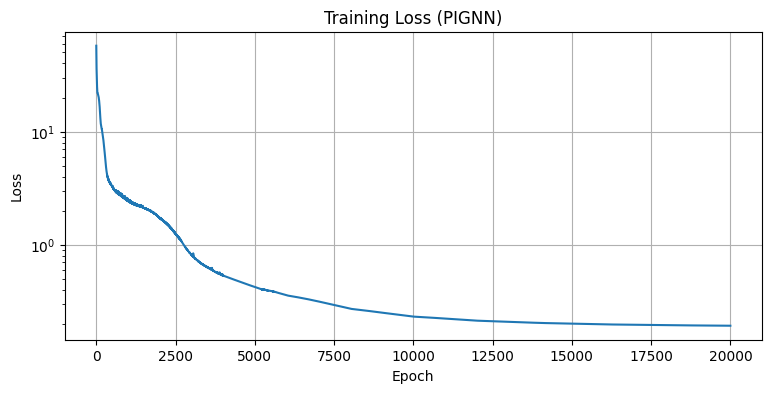

In [44]:
plt.figure(figsize=(9, 4))
plt.plot(loss_history)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss (PIGNN)")
plt.grid(True)
plt.show()

In [45]:
# Optional L-BFGS fine-tuning, same as the PINN notebook
optimizer_lbfgs = torch.optim.LBFGS(
    model.parameters(),
    max_iter=500,
    tolerance_grad=1e-6,
    tolerance_change=1e-8,
    history_size=50,
    line_search_fn="strong_wolfe",
)

def closure():
    optimizer_lbfgs.zero_grad()
    loss = loss_func_gnn(model)
    loss.backward()
    return loss

optimizer_lbfgs.step(closure)

tensor(0.1934, device='cuda:0', grad_fn=<AddBackward0>)

## 7. Visualization (same plotting functions as the PINN notebook)

A GNN needs a graph to run message passing on, so to evaluate the field on a fresh, dense scatter of
points for plotting we build a **new** k-NN graph over those query points and run the trained model on it
-- the network itself doesn't change, only the point cloud it's evaluated on (comparable to re-meshing a
mesh-based solver for a finer visualization grid). Once we have `(x, y, u, v, p)` back, we reuse the exact
same `postProcess_*` plotting functions from the PINN notebook unchanged, so the figures line up
side-by-side.

In [46]:
def get_pignn_field(model, xmin, xmax, ymin, ymax, N=60000, k=8):
    x = np.random.uniform(xmin, xmax, N)
    y = np.random.uniform(ymin, ymax, N)

    mask = (x - xc) ** 2 + (y - yc) ** 2 >= R ** 2
    x, y = x[mask], y[mask]

    XY = np.stack([x, y], axis=1).astype(np.float32)
    edge_np, _ = build_knn_edges(XY, k=k)

    XY_t = torch.tensor(XY, dtype=torch.float32).to(device)
    edge_t = torch.tensor(edge_np, dtype=torch.long).to(device)

    with torch.no_grad():
        uvp = model(XY_t, edge_t).cpu().numpy()

    u, v, p = uvp[:, 0], uvp[:, 1], uvp[:, 2]
    return [x, y, u, v, p]

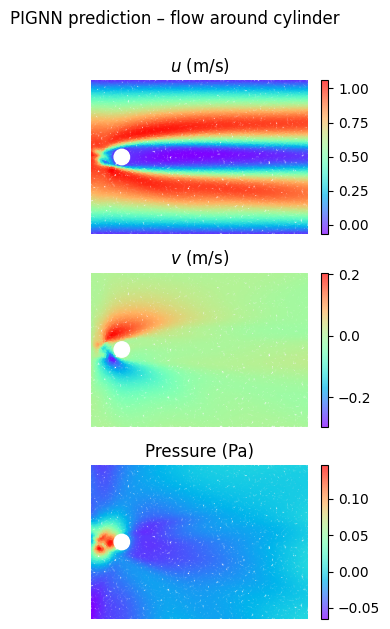

In [47]:
def postProcess_PIGNN(xmin, xmax, ymin, ymax, field_PIGNN, s=2, alpha=0.7, marker='o'):
    x, y, u, v, p = field_PIGNN

    fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(4, 7))
    fig.subplots_adjust(hspace=0.25)

    fields = [(u, r'$u$ (m/s)'), (v, r'$v$ (m/s)'), (p, 'Pressure (Pa)')]

    for i, (val, title) in enumerate(fields):
        cf = ax[i].scatter(x, y, c=val, s=s, cmap='rainbow', alpha=alpha, edgecolors='none', marker=marker)
        circle = plt.Circle((xc, yc), R, color='white', zorder=10)
        ax[i].add_patch(circle)
        ax[i].set_aspect('equal')
        ax[i].set_xlim([xmin, xmax])
        ax[i].set_ylim([ymin, ymax])
        ax[i].set_xticks([])
        ax[i].set_yticks([])
        ax[i].set_title(title)
        for spine in ax[i].spines.values():
            spine.set_visible(False)
        fig.colorbar(cf, ax=ax[i], fraction=0.046, pad=0.04)

    plt.suptitle("PIGNN prediction – flow around cylinder", fontsize=12)
    plt.show()


field_PIGNN = get_pignn_field(model, x_min, x_max, y_min, y_max)
postProcess_PIGNN(x_min, x_max, y_min, y_max, field_PIGNN)

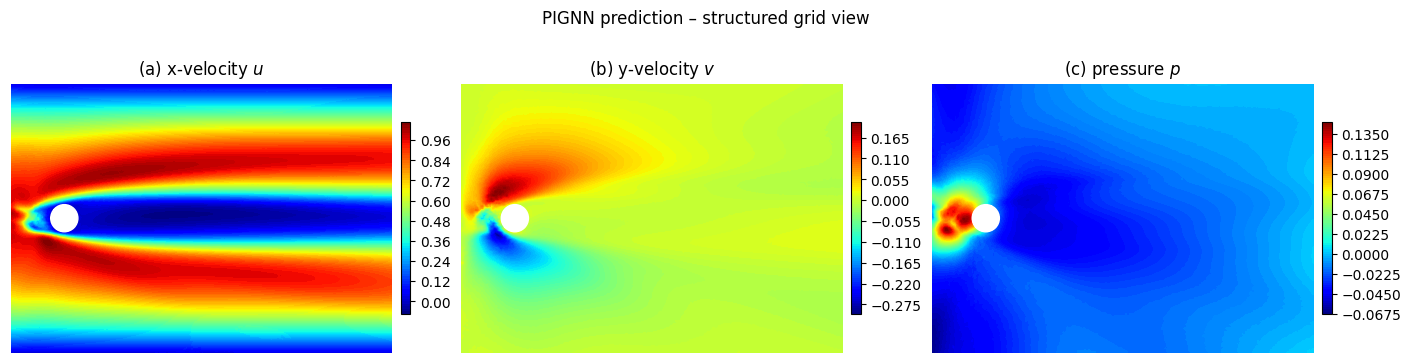

In [48]:
def postProcess_PIGNN1(xmin, xmax, ymin, ymax, field_PIGNN, nx=300, ny=150):
    x, y, u, v, p = field_PIGNN

    xi = np.linspace(xmin, xmax, nx)
    yi = np.linspace(ymin, ymax, ny)
    X, Y = np.meshgrid(xi, yi)

    Ui = griddata((x, y), u, (X, Y), method='cubic')
    Vi = griddata((x, y), v, (X, Y), method='cubic')
    Pi = griddata((x, y), p, (X, Y), method='cubic')

    mask = (X - xc) ** 2 + (Y - yc) ** 2 <= R ** 2
    Ui[mask] = np.nan
    Vi[mask] = np.nan
    Pi[mask] = np.nan

    fig, ax = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
    fields = [(Ui, r'(a) x-velocity $u$'), (Vi, r'(b) y-velocity $v$'), (Pi, r'(c) pressure $p$')]

    for i, (val, title) in enumerate(fields):
        cf = ax[i].contourf(X, Y, val, levels=100, cmap='jet')
        circle = plt.Circle((xc, yc), R, color='white', zorder=10)
        ax[i].add_patch(circle)
        ax[i].set_aspect('equal')
        ax[i].set_xlim(xmin, xmax)
        ax[i].set_ylim(ymin, ymax)
        ax[i].set_xticks([])
        ax[i].set_yticks([])
        ax[i].set_title(title)
        for spine in ax[i].spines.values():
            spine.set_visible(False)
        fig.colorbar(cf, ax=ax[i], fraction=0.025, pad=0.02)

    plt.suptitle("PIGNN prediction – structured grid view", fontsize=12)
    plt.show()


field_PIGNN = get_pignn_field(model, x_min, x_max, y_min, y_max)
postProcess_PIGNN1(x_min, x_max, y_min, y_max, field_PIGNN)

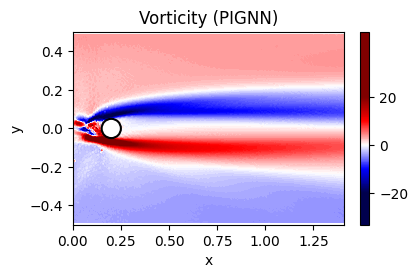

In [49]:
def postProcess_PIGNN_vorticity(xmin, xmax, ymin, ymax, field_PIGNN, nx=600, ny=200, omega_max=3):
    x, y, u, v, _ = field_PIGNN

    xi = np.linspace(xmin, xmax, nx)
    yi = np.linspace(ymin, ymax, ny)
    X, Y = np.meshgrid(xi, yi)

    Ui = griddata((x, y), u, (X, Y), method='cubic')
    Vi = griddata((x, y), v, (X, Y), method='cubic')

    dx = xi[1] - xi[0]
    dy = yi[1] - yi[0]

    dVdx = np.gradient(Vi, dx, axis=1)
    dUdy = np.gradient(Ui, dy, axis=0)
    omega = dVdx - dUdy

    mask = (X - xc) ** 2 + (Y - yc) ** 2 <= R ** 2
    omega[mask] = np.nan

    fig, ax = plt.subplots(figsize=(10, 2.5))
    cf = ax.contourf(X, Y, omega, levels=200, cmap='seismic', vmin=-omega_max, vmax=omega_max)
    circle = plt.Circle((xc, yc), R, color='black', fill=False, linewidth=1.5)
    ax.add_patch(circle)

    ax.set_aspect('equal')
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title("Vorticity (PIGNN)", fontsize=12)
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    cbar = plt.colorbar(cf, ax=ax, fraction=0.025, pad=0.02)
    cbar.set_ticks([-omega_max, 0, omega_max])
    plt.show()


postProcess_PIGNN_vorticity(x_min, x_max, y_min, y_max, field_PIGNN=field_PIGNN, omega_max=20)

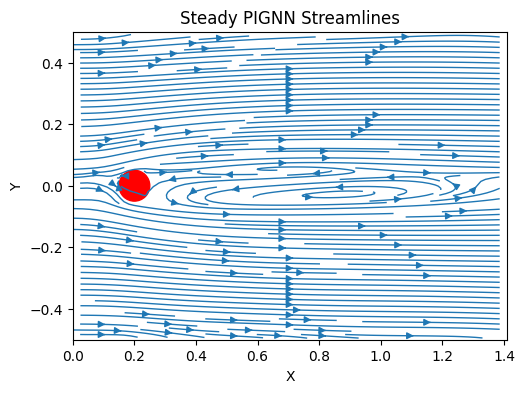

In [50]:
import matplotlib.tri as tri

field_PIGNN = get_pignn_field(model, x_min, x_max, y_min, y_max)
x, y, u, v, _ = field_PIGNN

nx, ny = 300, 200
grid_x = np.linspace(x_min, x_max, nx)
grid_y = np.linspace(y_min, y_max, ny)
GX, GY = np.meshgrid(grid_x, grid_y)

u_grid = griddata((x, y), u, (GX, GY), method='cubic')
v_grid = griddata((x, y), v, (GX, GY), method='cubic')

plt.figure(figsize=(8, 4))
plt.streamplot(GX, GY, u_grid, v_grid, density=2, linewidth=1)
circle = plt.Circle((xc, yc), R, color='red')
plt.gca().add_patch(circle)
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.gca().set_aspect('equal')
plt.title("Steady PIGNN Streamlines")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

## Notes / things worth tuning

- **If the loss still won't come down**: check `loss_pde` in isolation (print it separately from the
  weighted sum) — if it's stuck orders of magnitude above the BC losses, the stencil is likely under-
  resolved. First lever to pull is `K_GRAPH` (try 16-20 before touching anything else); second is `N_f`
  (more interior points = shorter average edge length = a locally more accurate quadratic fit).
- **`K_GRAPH`**: more neighbors → better-conditioned 5-unknown quadratic solve but more diffusive/smoothed
  derivative estimates; fewer → sharper but noisier. 12-20 is the reasonable range for a 2nd-order fit
  (below ~10 the 5x5 system gets close to rank-deficient).
- **`num_layers` in `PIGNN`**: each message-passing layer is one hop of information exchange between
  neighboring nodes; with `k=14` neighbors, 3 layers already lets information travel several
  point-spacings, which matters near the cylinder wake.
- **Cost vs. the PINN**: the PINN resamples nothing per epoch either, so wall-clock scaling is mostly about
  `N_nodes * K_GRAPH * num_layers` per forward pass vs. `N_f` pointwise evaluations. Expect PIGNN epochs to
  be noticeably slower for the same point count — this is inherent to message passing, not a bug.
- The loss weights (`w_pde/w_in/w_out/w_wall/w_cyl`) and the two-phase Adam then L-BFGS schedule are kept
  identical to the PINN notebook on purpose.